In [1]:
from pathlib import Path 
import numpy as np  # Numerical operations, including cumulative sums.
import pandas as pd  # Load and summarize tables.
import matplotlib.pyplot as plt  # Create figures and plotting areas.
import seaborn as sns  # Plot directly from table columns.
from IPython.display import display  # Display more than one table in a cell./

In [ ]:
# Q5: prepare data

from main import combined_datasets



df_Q5 = combined_datasets[
    [
        "Country name",
        "year",
        "Ladder score",
        "gdp_per_capita",
        "Working hours per worker"
    ]
].copy()

# Remove missing values
df_Q5 = df_Q5.dropna()

# Remove invalid values

valid_data_Q5 = df_Q5[
    (df_Q5["Working hours per worker"] > 0) &
    (df_Q5["Ladder score"] > 0) &
    (df_Q5["gdp_per_capita"] > 0)
]

# Count countries with complete data for each year
year_coverage = valid_data_Q5.groupby("year")[
    "Country name"
].nunique()


# Check Portugal's data
portugal_Q5 = df_Q5[
    df_Q5["Country name"] == "Portugal"
].sort_values("year")


display(df_Q5.head())
print(df_Q5.shape)







======================================= Working Hours dataset =======================================


Median working hours:  1990.65
Mean working hours:  2009.2943116729211
Number of countries: 130


Working Hours dataset head:
    Entity Code  year  Working hours per worker World region according to OWID
0  Albania  ALB  2005                   2343.90                         Europe
1  Albania  ALB  2006                   2333.12                         Europe
2  Albania  ALB  2007                   2334.51                         Europe
3  Albania  ALB  2008                   2195.57                         Europe
4  Albania  ALB  2009                   2191.19                         Europe


                                mean_working_hours
World region according to OWID                    
Africa                                 2021.635344
Asia                                   2240.156456
Europe                                 1828.705980
North America                        

,Country name,year,Ladder score,gdp_per_capita,Working hours per worker
0,Albania,2023,5.3040,9740.702341,2151.97
1,Albania,2022,5.2770,7756.961887,2160.98
2,Albania,2021,5.1990,7242.455131,2125.82
3,Albania,2020,5.1170,6027.913507,2042.15
4,Albania,2019,4.8827,6069.439031,2142.84


(1311, 5)


In [3]:
# Q5: calculate yearly average
# Three indicators used in Q5
metrics_Q5 = [
    "Ladder score",
    "gdp_per_capita",
    "Working hours per worker"
]

year_coverage_Q5 = (
    valid_data_Q5.groupby("year")[metrics_Q5]
    .mean()
    .reset_index()
)

display(year_coverage_Q5)

# Merge all countries with yearly averages

comparison_Q5 = pd.merge(
    valid_data_Q5,
    year_coverage_Q5,
    on="year",
    how="inner",
    suffixes=("_country", "_average"),
    validate="many_to_one"
)

# sort bu country and year
comparison_Q5 = comparison_Q5.sort_values(
    ["Country name", "year"]
)
display(comparison_Q5.head())

,year,Ladder score,gdp_per_capita,Working hours per worker
0,2011,5.586910,19156.291512,1946.191441
1,2012,5.618518,18945.065211,1948.107857
2,2014,5.586277,19548.064128,1943.213125
3,2015,5.583000,17280.139693,1943.947000
4,2016,5.573446,16997.583570,1950.032768
5,2017,5.593696,18108.478101,1945.316339
6,2018,5.653773,19680.247627,1931.606455
7,2019,5.697827,19054.965582,1923.658241
8,2020,5.722000,18167.305965,1843.680093
9,2021,5.702241,21068.509461,1905.704630


,Country name,year,Ladder score_country,gdp_per_capita_country,Working hours per worker_country,Ladder score_average,gdp_per_capita_average,Working hours per worker_average
11,Albania,2011,5.134,4465.709143,1852.72,5.586910,19156.291512,1946.191441
10,Albania,2012,5.550,4280.933163,2054.16,5.618518,18945.065211,1948.107857
9,Albania,2014,4.959,4793.597511,1946.22,5.586277,19548.064128,1943.213125
8,Albania,2015,4.655,4199.539129,1969.74,5.583000,17280.139693,1943.947000
7,Albania,2016,4.644,4457.634122,2059.25,5.573446,16997.583570,1950.032768


In [4]:
# Q5: Select a country
selected_country = "Portugal"

country_data_Q5 = comparison_Q5[
    comparison_Q5["Country name"] == selected_country
].sort_values("year")

display(country_data_Q5.head())

,Country name,year,Ladder score_country,gdp_per_capita_country,Working hours per worker_country,Ladder score_average,gdp_per_capita_average,Working hours per worker_average
982,Portugal,2011,5.327,23246.542542,1729.59,5.586910,19156.291512,1946.191441
981,Portugal,2012,5.101,20593.427422,1708.60,5.618518,18945.065211,1948.107857
980,Portugal,2014,5.102,22120.685013,1726.29,5.586277,19548.064128,1943.213125
979,Portugal,2015,5.123,19215.781301,1731.76,5.583000,17280.139693,1943.947000
978,Portugal,2016,5.195,19980.280887,1737.48,5.573446,16997.583570,1950.032768


In [5]:
# Q5: Create groups for line charts
def create_group_Q5(data, metric, country):

    long_data = data.melt(
        id_vars="year",
        value_vars=[
            f"{metric}_country",
            f"{metric}_average"
        ],
        var_name="Group",
        value_name="Value"
    )

    long_data["Group"] = long_data["Group"].replace({
        f"{metric}_country": country,
        f"{metric}_average": "Average"
    })

    return long_data

In [6]:
# Q5: Prepare grouped data for three metrics   To simplify the plotting code.


happiness_long_Q5 = create_group_Q5(
    country_data_Q5,
    "Ladder score",
    selected_country
)

gdp_long_Q5 = create_group_Q5(
    country_data_Q5,
    "gdp_per_capita",
    selected_country
)

hours_long_Q5 = create_group_Q5(
    country_data_Q5,
    "Working hours per worker",
    selected_country
)

display(happiness_long_Q5.head())

,year,Group,Value
0,2011,Portugal,5.327
1,2012,Portugal,5.101
2,2014,Portugal,5.102
3,2015,Portugal,5.123
4,2016,Portugal,5.195


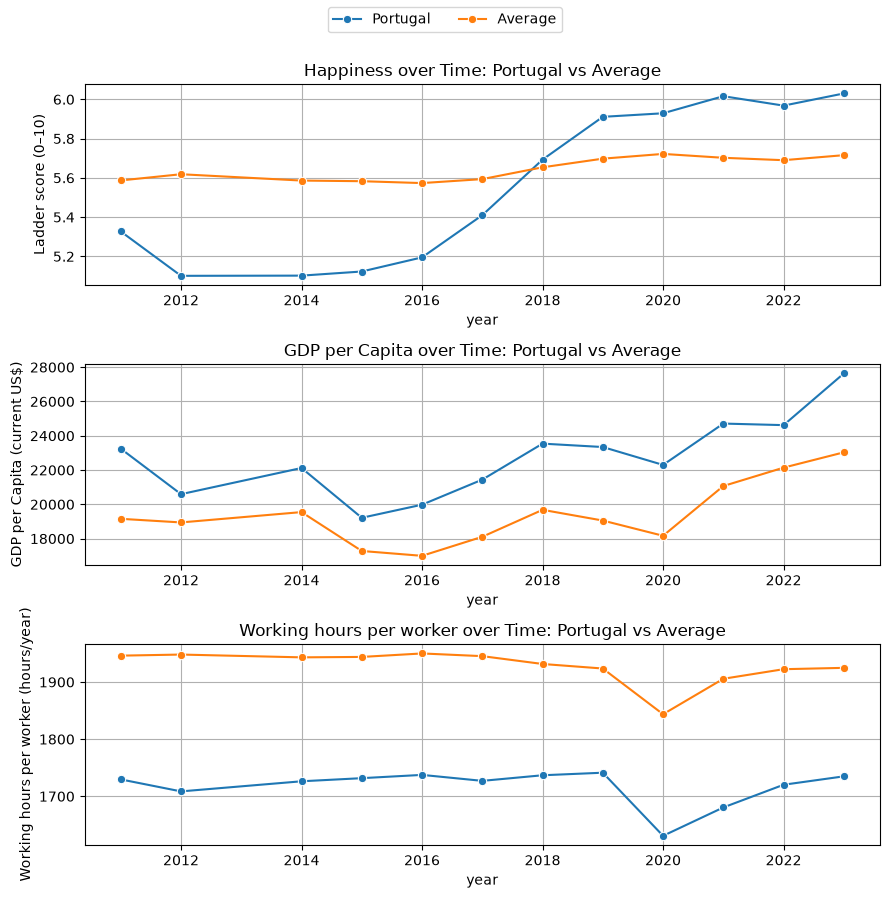

In [8]:
# Create the superimposed line chart here.
fig, tre = plt.subplots(3, 1, figsize=(9, 9))


# ---------------------------Happiness over time vs Average -------------------------------------------
# --Happiness
sns.lineplot(
    data=happiness_long_Q5,
    x="year",
    y="Value", 
    marker="o", 
    hue="Group",
    # legend=False,
    ax=tre[0]
    )

tre[0].set_title(f"Happiness over Time: {selected_country} vs Average")
tre[0].set_xlabel("year")
tre[0].set_ylabel("Ladder score (0–10)")
tre[0].grid(True)



# ---------------------------GDP per Capita over time vs Average -------------------------------------------
# GDP per Capita
sns.lineplot(
    data=gdp_long_Q5,
    x="year",
    y="Value", 
    marker="o", 
    hue="Group",
    legend=False,
    ax=tre[1]
    )

tre[1].set_title(f"GDP per Capita over Time: {selected_country} vs Average")
tre[1].set_xlabel("year")
tre[1].set_ylabel("GDP per Capita (current US$)")
tre[1].grid(True)




# ---------------------------Working hours per worker over time vs Average -------------------------------------------
# Working hours per worker
sns.lineplot(
    data=hours_long_Q5,
    x="year",
    y="Value", 
    marker="o", 
    hue="Group",
    legend=False,
    ax=tre[2]
    )

tre[2].set_title(f"Working hours per worker over Time: {selected_country} vs Average")
tre[2].set_xlabel("year")
tre[2].set_ylabel("Working hours per worker (hours/year)")
tre[2].grid(True)



# Display a shared legend at the top of the figure
# Get legend information from the first subplot
handles, labels = tre[0].get_legend_handles_labels()
tre[0].get_legend().remove()# remove legend of tre[0]
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()